# 07 · Monitoreo, reemplazo y negocio

Reconstruye alertas, comparación del candidato rechazado y valor de la priorización. Las etiquetas se usan solo en revisiones maduras. No se reentrena ni se cambia un alias.

**Alcance de validación.** 2014J ya se había observado en una versión anterior. **No es una prueba final independiente ni un hold-out de un solo uso.** Separar personas y ajustar transformaciones dentro de cada fold evita fugas directas, pero no elimina el conocimiento previo de sus resultados. Las cifras sobre 2014J describen este histórico; la decisión institucional necesita una cohorte futura sin consultar, con protocolo fijado antes de conocer resultados.

In [1]:
from pathlib import Path
import os, sys, json, hashlib
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p/'src/notebooks.py').is_file()), None)
if ROOT is None and (here/'proyecto_final/src/notebooks.py').is_file():
    ROOT = here/'proyecto_final'
assert ROOT is not None, 'Abrir desde proyecto_final o notebooks.'
sys.path.insert(0, str(ROOT))
os.environ['MPLCONFIGDIR'] = str(ROOT/'.local/matplotlib')
os.environ['PSET4_MODEL_MODE'] = 'fixture'
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.notebooks import evidencia
from src.datos import sha256
E = evidencia()
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 32)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
%matplotlib inline
print('Ejecución local de evidencia congelada. Sin llamadas LLM, nuevos entrenamientos ni cambios en Registry.')


Ejecución local de evidencia congelada. Sin llamadas LLM, nuevos entrenamientos ni cambios en Registry.


## Separar alerta de confirmación de desempeño

Sin resultado final disponible se observan los datos, pero no se calcula AP. Un cambio de distribución puede requerir revisar extracción o población; no demuestra por sí solo pérdida de valor.

,plan_id,lote_id,corte,ap_fail,umbral_ap,tp_acumulados,reentrenamiento_propuesto
8,oulad-2014j-control-v1,L04,14,0.438062,0.390610,26.0,False
9,oulad-2014j-control-v1,L08,28,0.433943,0.431508,77.0,False
10,oulad-2014j-control-v1,L01,14,0.397020,0.349481,19.0,False
11,oulad-2014j-control-v1,L02,14,0.387175,0.445454,50.0,False
12,oulad-2014j-control-v1,L03,14,0.322372,0.371918,26.0,True
13,oulad-2014j-control-v1,L05,28,0.431534,0.404330,66.0,False
14,oulad-2014j-control-v1,L06,28,0.395385,0.470453,172.0,False
15,oulad-2014j-control-v1,L07,28,0.330967,0.412365,105.0,True
24,oulad-2014j-deriva-v1,L04,14,0.438062,0.390610,26.0,False
25,oulad-2014j-deriva-v1,L08,28,0.433943,0.431508,77.0,False


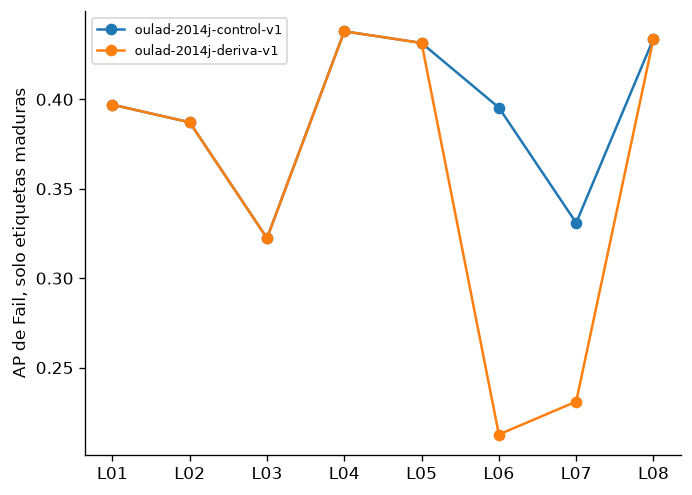

,alertas
plan_id,
oulad-2014j-control-v1,12
oulad-2014j-deriva-v1,16


In [2]:
mon=pd.read_csv(ROOT/'docs/monitoreo.csv'); alerts=pd.read_csv(ROOT/'docs/alertas.csv'); retrain=pd.read_csv(ROOT/'docs/reentrenamientos.csv')
assert len(mon)==32 and len(alerts)==28 and len(retrain)==4
pending=mon.loc[~mon.desempeno_evaluable]; mature=mon.loc[mon.desempeno_evaluable]
assert len(pending)==16 and pending.ap_fail.isna().all()
assert mature.ap_fail.notna().all()
display(mature[['plan_id','lote_id','corte','ap_fail','umbral_ap','tp_acumulados','reentrenamiento_propuesto']])
for plan,g in mature.groupby('plan_id'):
    g=g.sort_values('lote_id');plt.plot(g.lote_id,g.ap_fail,marker='o',label=plan)
plt.ylabel('AP de Fail, solo etiquetas maduras');plt.legend(fontsize=8);plt.show()
display(alerts.groupby('plan_id').size().rename('alertas').to_frame())


## Por qué se rechazó el candidato

Con 147 cupos detectó cuatro Fail más, pero la regla previa exigía al menos siete. Rechazar evita cambiar el modelo por una ganancia menor que el margen acordado; la versión 1 sigue activa.

In [3]:
from src.reentrenar import regla_promocion
display(retrain[['evento','tp_champion','tp_challenger','tp_estatico','sigma_politica','elegible_promocion','decision']])
last=retrain.iloc[-1]
assert last['estado']=='RECHAZADO' and last['decision']=='rechazar' and not bool(last['elegible_promocion'])
comparison=json.loads(retrain.loc[retrain.evento.eq('COMPARADO'),'contenido'].iloc[0])
rule=regla_promocion(comparison['modelos']['champion'], comparison['modelos']['challenger'], float(last.sigma_politica))
display(pd.DataFrame([rule]))
assert rule['elegible_promocion'] is False and rule['ganancia_tp']==4 and rule['ganancia_tp_minima']==7
assert comparison['auditoria']['solapamiento_personas']==0
print('2014J y L08 no sustituyen una cohorte prospectiva independiente.')


,evento,tp_champion,tp_challenger,tp_estatico,sigma_politica,elegible_promocion,decision
0,SOLICITADO,77,81,54,0.016598,False,NaN
1,DECISION_SOLICITADA,77,81,54,0.016598,False,rechazar
2,COMPARADO,77,81,54,0.016598,False,NaN
3,DECIDIDO,77,81,54,0.016598,False,rechazar


,metrica,ganancia_tp,ganancia_cobertura,sigma_politica,ganancia_tp_minima,elegible_promocion,aprobacion_humana_requerida,recomendacion
0,cobertura_fail,4,0.011019,0.016598,7,False,True,rechazar


2014J y L08 no sustituyen una cohorte prospectiva independiente.


## Valor a igual capacidad y riesgo presupuestario

La mejora de negocio es relativa: 420 frente a 314 Fail entre 920 propuestas. No se observa el efecto de una tutoría. Las filas L05–L08 ya acumulan las propuestas previas: no se suman de nuevo L01–L04.

,cupos,tp,fp,fail_base,cobertura,precision
politica,,,,,,
estatico,920,314,606,1947,0.161274,0.341304
longitudinal,920,420,500,1947,0.215716,0.456522


Mejora relativa de detección: 33.76%; meta mínima: 10%.


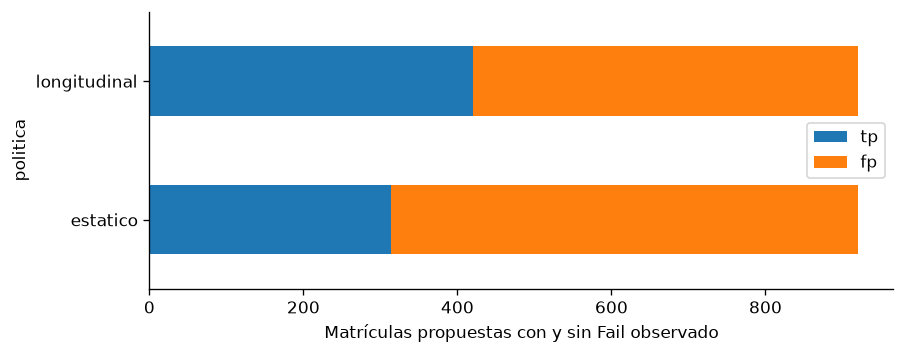

Adelanto del 30%: supuesto por edición, 274 cupos, no 276 al redondear globalmente.
Solo adelanto: 152 TP y 122 FP. Prevención + adelanto: 530 TP y 664 FP con 1194 cupos.
No se han medido costos, asistencia, efecto causal o ahorro. Mantener protección del presupuesto reactivo vigente.


In [4]:
lots=pd.DataFrame(E['lotes_negocio'])
base=lots.loc[lots.capacidad.eq('referencia') & lots.tiempo.eq('dos_rondas') & lots.cohorte_id.ne('GLOBAL')]
final=base.loc[base.lote_id.isin(['L05','L06','L07','L08']) & base.plan_id.eq('oulad-2014j-control-v1') & base.politica.isin(['longitudinal','estatico'])]
summary=final.groupby('politica')[['cupos','tp','fp','fail_base']].sum()
summary['cobertura']=summary.tp/summary.fail_base;summary['precision']=summary.tp/summary.cupos
display(summary)
assert summary.loc['longitudinal','tp']==420 and summary.loc['estatico','tp']==314
assert summary.cupos.eq(920).all()
improvement=summary.loc['longitudinal','tp']/summary.loc['estatico','tp']-1
print(f'Mejora relativa de detección: {100*improvement:.2f}%; meta mínima: 10%.')
summary[['tp','fp']].plot.barh(stacked=True,figsize=(8,3));plt.xlabel('Matrículas propuestas con y sin Fail observado');plt.show()
print('Adelanto del 30%: supuesto por edición, 274 cupos, no 276 al redondear globalmente.')
print('Solo adelanto: 152 TP y 122 FP. Prevención + adelanto: 530 TP y 664 FP con 1194 cupos.')
print('No se han medido costos, asistencia, efecto causal o ahorro. Mantener protección del presupuesto reactivo vigente.')


## Acceso al apoyo y revisión humana

Solo se analiza el escenario original, con resultados maduros. N indica que no consta discapacidad declarada; Y, que sí consta. Cobertura y falsas alarmas usan la base inicial; AP y tasas de decisión, las matrículas elegibles en cada corte. Un promedio favorable no descarta una brecha de acceso por lote.

In [5]:
equity=pd.DataFrame(E['etica_subgrupos'])
gaps=pd.DataFrame(E['etica_brechas'])
display(equity.loc[equity.ambito.eq('global') & equity.corte.eq(28)])
display(gaps.loc[gaps.revision.eq(True)])
assert gaps.revision.any()
print('L06 requiere revisión académica antes de ampliar uso. Una alerta no prueba discriminación causal.')
print('El estudiante debe poder pedir revisión; la propuesta no se convierte automáticamente en atención.')


,ambito,unidad,corte,grupo,n,personas,...,fp_acumulado,fn_acumulado,cobertura_acumulada,fpr_acumulada,tasa_propuesta_acumulada,equidad_evaluable
36,global,todos,28,N,8250,7934,...,462,1352,0.218949,0.069547,0.100430,True
37,global,todos,28,Y,842,810,...,38,175,0.189815,0.059282,0.092182,True
38,global,todos,28,sin_dato,0,0,...,0,0,NaN,NaN,NaN,False


,ambito,unidad,corte,evaluable,brecha_cobertura,brecha_fpr,revision
21,lote,L06,28,True,-0.082016,0.011552,True


L06 requiere revisión académica antes de ampliar uso. Una alerta no prueba discriminación causal.
El estudiante debe poder pedir revisión; la propuesta no se convierte automáticamente en atención.


## Lectura final

Los resultados reproducidos pertenecen a los experimentos registrados. La fecha de ejecución de este notebook no los convierte en evidencia nueva de generalización. Consulte `README.md` para insumos, dependencias y comandos del pipeline completo.